# 04 · Second year (2024) and sampling uncertainty

1. Replicate **2024** with the same code — a second, independent test of the pipeline
2. Measure the **2024 → 2025 change** nationally, by urban/rural and by department
3. Attach **approximate 95% confidence intervals** and compare our significance calls
   with the ones DANE marks in its own publications

**Important limitation.** The public microdata contain the expansion factors but **no stratum
or primary-sampling-unit (cluster) identifiers**. Proper design-based standard errors (e.g. with
`samplics`) need both. The intervals here use Taylor linearization of the ratio estimator, with
households as sampling units and the 25 survey domains (`dominio`) as strata. Ignoring clustering
almost always makes standard errors **too small**, so these intervals are a lower bound on the
true uncertainty.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from povcol.load import load
from povcol.weighted import weighted_rate, gini, ratio_se
from povcol import official

RESULTS = ROOT / "results"; RESULTS.mkdir(exist_ok=True)
FIGS = ROOT / "figures"; FIGS.mkdir(exist_ok=True)
Z = 1.96

data = {}
for year in (2024, 2025):
    h = load(year, "hogares")
    h["w_person"] = h["fex"] * h["nper"]
    h["w_dpto"] = h["fex_dpto"] * h["nper"]
    h["poor_persons"] = h["pobre"] * h["nper"]          # same definition as the replication
    h["extreme_persons"] = h["indigente"] * h["nper"]
    data[year] = h
    print(year, h.shape, "column map:", h.attrs["column_map"])

2024 (275057, 27) column map: {'directorio': 'directorio', 'secuencia_p': 'secuencia_p', 'clase': 'clase', 'dpto': 'dpto', 'dominio': 'dominio', 'fex': 'fex_c', 'fex_dpto': 'fex_dpto', 'npobres': 'npobres', 'nindigentes': 'nindigentes', 'ingpcug': 'ingpcug', 'lp': 'lp', 'li': 'li', 'pobre': 'pobre', 'indigente': 'indigente', 'npersug': 'npersug', 'nper': 'nper'}
2025 (276666, 27) column map: {'directorio': 'directorio', 'secuencia_p': 'secuencia_p', 'clase': 'clase', 'dpto': 'dpto', 'dominio': 'dominio', 'fex': 'fex_c', 'fex_dpto': 'fex_dpto', 'npobres': 'npobres', 'nindigentes': 'nindigentes', 'ingpcug': 'ingpcug', 'lp': 'lp', 'li': 'li', 'pobre': 'pobre', 'indigente': 'indigente', 'npersug': 'npersug', 'nper': 'nper'}


## 1. Replication of 2024

In [2]:
def domains(h):
    return {"nacional": h, "cabeceras": h[h["clase"] == 1], "rural": h[h["clase"] == 2]}

rows = []
for year, h in data.items():
    for dom, d in domains(h).items():
        rows += [
            {"year": year, "domain": dom, "indicator": "Monetary poverty (%)",
             "this_repo": weighted_rate(d["pobre"], d["w_person"]), "DANE": official.POVERTY[(year, dom)]},
            {"year": year, "domain": dom, "indicator": "Extreme poverty (%)",
             "this_repo": weighted_rate(d["indigente"], d["w_person"]), "DANE": official.EXTREME[(year, dom)]},
            {"year": year, "domain": dom, "indicator": "Gini",
             "this_repo": gini(d["ingpcug"], d["w_person"]), "DANE": official.GINI[(year, dom)]},
        ]
rep = pd.DataFrame(rows)
rep["difference"] = rep["this_repo"] - rep["DANE"]
rep.to_csv(RESULTS / "replication_2024_2025.csv", index=False)
rep.pivot_table(index=["domain", "indicator"], columns="year",
                values=["this_repo", "DANE", "difference"]).round(3)

DANE         difference        this_repo  \
year                              2024    2025       2024   2025      2024   
domain    indicator                                                          
cabeceras Extreme poverty (%)    8.700   6.900     -0.025 -0.047     8.675   
          Gini                   0.530   0.507     -0.000  0.000     0.530   
          Monetary poverty (%)  28.600  24.600      0.010  0.008    28.610   
nacional  Extreme poverty (%)   11.700   9.600     -0.010  0.038    11.690   
          Gini                   0.551   0.531     -0.000 -0.000     0.551   
          Monetary poverty (%)  31.800  28.000     -0.014  0.003    31.786   
rural     Extreme poverty (%)   21.800  19.100      0.040 -0.043    21.840   
          Gini                   0.482   0.476      0.000  0.000     0.482   
          Monetary poverty (%)  42.500  39.500     -0.020 -0.016    42.480   

                                        
year                              2025  
domain    indicator                     
cabeceras Extreme poverty (%)    6.853  
          Gini                   0.507  
          Monetary poverty (%)  24.608  
nacional  Extreme poverty (%)    9.638  
          Gini                   0.531  
          Monetary poverty (%)  28.003  
rural     Extreme poverty (%)   19.057  
          Gini                   0.476  
          Monetary poverty (%)  39.484

## 2. Change 2024 → 2025 with approximate 95% confidence intervals

In [3]:
def estimate(d, y_col, weight="fex"):
    R, se = ratio_se(d[y_col], d["nper"], d[weight], d["dominio"])
    return 100 * R, 100 * se

rows = []
for dom in ["nacional", "cabeceras", "rural"]:
    for ind, col in [("poverty", "poor_persons"), ("extreme", "extreme_persons")]:
        r = {"domain": dom, "indicator": ind}
        for year in (2024, 2025):
            est, se = estimate(domains(data[year])[dom], col)
            r[f"{year}"] = est
            r[f"se_{year}"] = se
        r["change_pp"] = r["2025"] - r["2024"]
        # independent samples in the two years -> variances add
        r["se_change"] = np.hypot(r["se_2024"], r["se_2025"])
        r["ci_low"] = r["change_pp"] - Z * r["se_change"]
        r["ci_high"] = r["change_pp"] + Z * r["se_change"]
        r["significant_95"] = (r["ci_low"] > 0) | (r["ci_high"] < 0)
        rows.append(r)
change = pd.DataFrame(rows)
change.to_csv(RESULTS / "change_2024_2025.csv", index=False)
change.round(2)

,domain,indicator,2024,se_2024,2025,se_2025,change_pp,se_change,ci_low,ci_high,significant_95
0,nacional,poverty,31.79,0.17,28.00,0.17,-3.78,0.24,-4.26,-3.31,True
1,nacional,extreme,11.69,0.12,9.64,0.11,-2.05,0.17,-2.38,-1.72,True
2,cabeceras,poverty,28.61,0.19,24.61,0.18,-4.00,0.26,-4.51,-3.49,True
3,cabeceras,extreme,8.68,0.12,6.85,0.10,-1.82,0.16,-2.13,-1.52,True
4,rural,poverty,42.48,0.40,39.48,0.41,-3.00,0.57,-4.11,-1.88,True
5,rural,extreme,21.84,0.35,19.06,0.34,-2.78,0.49,-3.75,-1.82,True


DANE reports the national (−3.8 pp), urban (−4.0 pp) and rural (−3.0 pp) poverty declines as
statistically significant at 95%. Our approximate intervals agree on all three.

## 3. Departments: change and significance

In [4]:
rows = []
for dpto in sorted(data[2025]["dpto"].unique()):
    r = {"department": dpto}
    for year in (2024, 2025):
        d = data[year][data[year]["dpto"] == dpto]
        r[f"{year}"], r[f"se_{year}"] = estimate(d, "poor_persons", weight="fex_dpto")
        r[f"DANE_{year}"] = official.DEPT_POVERTY[dpto][0 if year == 2024 else 1]
    r["change_pp"] = r["2025"] - r["2024"]
    r["se_change"] = np.hypot(r["se_2024"], r["se_2025"])
    r["significant_95"] = abs(r["change_pp"]) > Z * r["se_change"]
    rows.append(r)
dchange = pd.DataFrame(rows).set_index("department").sort_values("change_pp")
dchange["diff_vs_DANE_2024"] = dchange["2024"] - dchange["DANE_2024"]
dchange["diff_vs_DANE_2025"] = dchange["2025"] - dchange["DANE_2025"]
dchange.to_csv(RESULTS / "departments_change_2024_2025.csv")
print(f"Largest |difference| vs DANE: 2024 {dchange['diff_vs_DANE_2024'].abs().max():.2f} pp, "
      f"2025 {dchange['diff_vs_DANE_2025'].abs().max():.2f} pp")
dchange[["2024", "2025", "change_pp", "se_change", "significant_95"]].round(2)

Largest |difference| vs DANE: 2024 0.12 pp, 2025 0.04 pp


,2024,2025,change_pp,se_change,significant_95
department,,,,,
Tolima,35.63,27.97,-7.66,1.17,True
Nariño,39.20,33.40,-5.80,1.36,True
Sucre,57.50,51.83,-5.67,1.28,True
Córdoba,49.56,43.97,-5.59,1.56,True
La Guajira,65.72,60.16,-5.57,1.42,True
Antioquia,24.66,19.18,-5.48,0.81,True
Magdalena,51.67,46.51,-5.16,1.19,True
Quindío,25.87,20.94,-4.92,0.90,True
Cundinamarca,19.98,15.14,-4.84,1.09,True


**Check against DANE's significance calls.** DANE's departmental press release marks with an
asterisk which 2024→2025 changes are significant. Where both sources make a call we can compare.
Because our standard errors ignore clustering, we expect to call *more* changes significant than
DANE, never fewer.

In [5]:
DANE_SIG = {  # cp-PMDepartamental-2025.pdf, chart "Variación de la incidencia ... 2024-2025"
    "Tolima": True, "Nariño": True, "Sucre": True, "Córdoba": True, "La Guajira": True,
    "Antioquia": True, "Magdalena": True, "Quindío": True, "Cundinamarca": True,
    "Atlántico": True, "Valle del Cauca": True, "Risaralda": True, "Cesar": True,
    "Santander": True, "Bolívar": True, "Caldas": True, "Bogotá D.C.": True,
    "Caquetá": False, "Cauca": False, "Chocó": False, "Norte de Santander": False,
    "Meta": False, "Huila": False, "Boyacá": False,
}
cmp = dchange.loc[list(DANE_SIG), ["change_pp", "se_change", "significant_95"]].copy()
cmp["DANE_significant"] = pd.Series(DANE_SIG)
cmp["agree"] = cmp["significant_95"] == cmp["DANE_significant"]
print(f"Agreement with DANE on {cmp['agree'].sum()} of {len(cmp)} departments")
cmp.round(2)

Agreement with DANE on 24 of 24 departments


,change_pp,se_change,significant_95,DANE_significant,agree
department,,,,,
Tolima,-7.66,1.17,True,True,True
Nariño,-5.80,1.36,True,True,True
Sucre,-5.67,1.28,True,True,True
Córdoba,-5.59,1.56,True,True,True
La Guajira,-5.57,1.42,True,True,True
Antioquia,-5.48,0.81,True,True,True
Magdalena,-5.16,1.19,True,True,True
Quindío,-4.92,0.90,True,True,True
Cundinamarca,-4.84,1.09,True,True,True


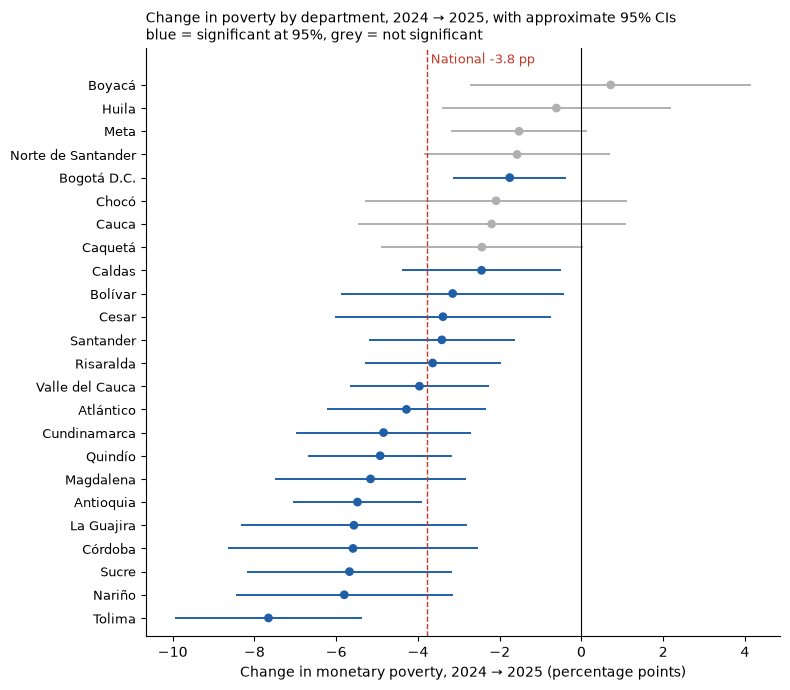

In [6]:
d = dchange.sort_values("change_pp")
fig, ax = plt.subplots(figsize=(8, 7))
y = np.arange(len(d))
colors = np.where(d["significant_95"], "#1f5fa8", "#b0b0b0")
ax.errorbar(d["change_pp"], y, xerr=Z * d["se_change"], fmt="none", ecolor=colors, elinewidth=1.4, capsize=0)
ax.scatter(d["change_pp"], y, color=colors, zorder=3, s=28)
ax.axvline(0, color="black", lw=0.8)
nat = change.query("domain == 'nacional' and indicator == 'poverty'")["change_pp"].iloc[0]
ax.axvline(nat, color="#c0392b", ls="--", lw=1)
ax.text(nat, len(d) - 0.2, f" National {nat:+.1f} pp", color="#c0392b", fontsize=9, va="bottom")
ax.set_yticks(y)
ax.set_yticklabels(d.index, fontsize=9)
ax.set_ylim(-0.8, len(d) + 0.6)
ax.set_xlabel("Change in monetary poverty, 2024 → 2025 (percentage points)")
ax.set_title("Change in poverty by department, 2024 → 2025, with approximate 95% CIs\n"
             "blue = significant at 95%, grey = not significant", loc="left", fontsize=10)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
fig.tight_layout()
fig.savefig(FIGS / "poverty_change_by_department.png", dpi=200)
plt.show()

## 4. Notes for the write-up

- The same code replicates both 2024 and 2025, so the result is not tuned to one file.
- National poverty fell from about 31.8% to 28.0% (−3.8 pp). The approximate interval is far
  from zero, in line with DANE's significance call.
- Department-level intervals are wide (a few thousand households each); some large-looking
  changes are not distinguishable from zero.
- All intervals here are approximate lower bounds: no cluster identifiers in the public file.